# Generates Confusion Matrices for the Specified Models

In [1]:
import torch

class ResNetClassifier(torch.nn.Module):
    def __init__(self, resnetmodel):
        super(ResNetClassifier, self).__init__()
        # ResNet structure (without classifier)
        self.resnet = torch.nn.Sequential(resnetmodel.conv1,
                                            resnetmodel.bn1,
                                            resnetmodel.relu,
                                            resnetmodel.maxpool,
                                            resnetmodel.layer1,
                                            resnetmodel.layer2,
                                            resnetmodel.layer3,
                                            resnetmodel.layer4,
                                            resnetmodel.avgpool)
        # 2048 from the resnet convolution and 1 from the angles
        self.classifier = torch.nn.Sequential(torch.nn.Linear(2049, 256),
                                              torch.nn.Linear(256, 23))
    
    def forward(self, X, angles):
        r = self.resnet(X)
        f = torch.flatten(r, 1)
        f = torch.cat([f, angles], dim=1)
        y = self.classifier(f)
        return y

class ResNetRegressor(torch.nn.Module):
    def __init__(self, resnetmodel):
        super(ResNetRegressor, self).__init__()
        # ResNet structure (without classifier)
        self.resnet = torch.nn.Sequential(resnetmodel.conv1,
                                            resnetmodel.bn1,
                                            resnetmodel.relu,
                                            resnetmodel.maxpool,
                                            resnetmodel.layer1,
                                            resnetmodel.layer2,
                                            resnetmodel.layer3,
                                            resnetmodel.layer4,
                                            resnetmodel.avgpool)
        # 2048 from the resnet convolution and 1 from the angles
        self.regressor = torch.nn.Sequential(torch.nn.Linear(2049, 256),
                                             torch.nn.Linear(256, 1))
    
    def forward(self, X, angles):
        r = self.resnet(X)
        f = torch.flatten(r, 1)
        f = torch.cat([f, angles], dim=1)
        y = self.regressor(f)
        return y

In [2]:
device = torch.device('cpu') 
if torch.cuda.is_available():
    device = torch.device('cuda') # rose laptops and the servers
elif torch.backends.mps.is_available():
    device = torch.device('mps') # mac
print('Using device:', device)

Using device: cuda


In [35]:
import copy, torchvision

# Load models
resnet50 = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
classifier = ResNetClassifier(copy.deepcopy(resnet50)).to(device)
regressor = ResNetRegressor(copy.deepcopy(resnet50)).to(device)

classifier.load_state_dict(torch.load("resnet_finetuned_double_FULL.pth", weights_only=True))
regressor.load_state_dict(torch.load("resnet_finetuned_regressor_double_FULL.pth", weights_only=True))

classifier.eval()
regressor.eval()

# Load saved test data
classifier_testloader = torch.load("test_data_classifier.pt", weights_only=False)
regressor_testloader = torch.load("test_data_regressor.pt", weights_only=False)

# Test models
classifier_predictions = []
for image, angle, grade in classifier_testloader.dataset:
    image = image.to(device)
    angle = torch.from_numpy(angle).to(device)

    output = classifier(image.unsqueeze(0), angle.unsqueeze(0))
    classifier_predictions.append(torch.argmax(output, dim=1).item())

regressor_predictions = []
for image, angle, grade in regressor_testloader.dataset:
    image = image.to(device)
    angle = torch.from_numpy(angle).to(device)
    
    output = regressor(image.unsqueeze(0), angle.unsqueeze(0))
    regressor_predictions.append(output.round().item())

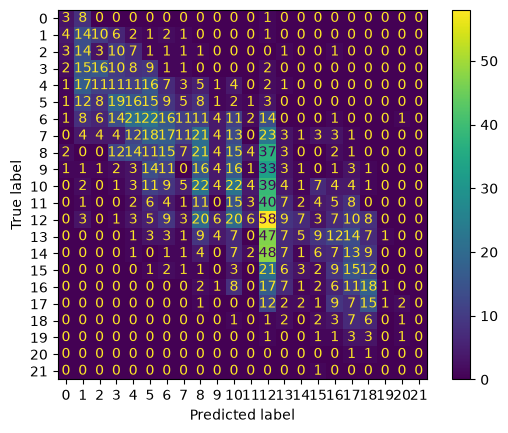

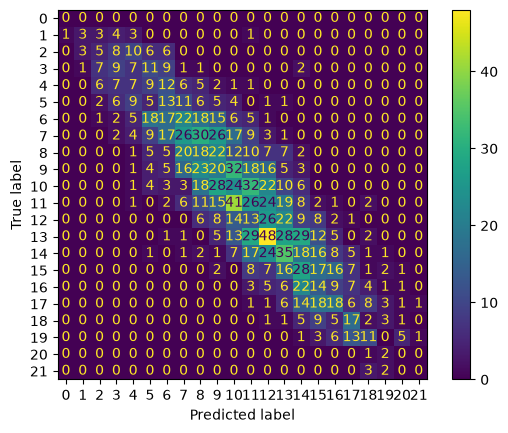

In [40]:
# Generate confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

grade_map = {
  10: "4a",
  11: "4b",
  12: "4c",
  13: "5a",
  14: "5b",
  15: "5c",
  16: "6a",
  17: "6a+",
  18: "6b",
  19: "6b+",
  20: "6c",
  21: "6c+",
  22: "7a",
  23: "7a+",
  24: "7b",
  25: "7b+",
  26: "7c",
  27: "7c+",
  28: "8a",
  29: "8a+",
  30: "8b",
  31: "8b+",
  32: "8c",
  33: "8c+",
}

# classifier_grades = list(map(lambda x: grade_map[(x + 10).item()], classifier_testloader.dataset.grades))
# regressor_grades = list(map(lambda x: grade_map[(x + 10).item()], regressor_testloader.dataset.grades))

# classifier_classes = list(map(lambda x: grade_map[x + 10], classifier_predictions))
# regressor_classes = list(map(lambda x: grade_map[round(x) + 10] if round(x) >= 0 and round(x) <= 23 else -1, regressor_predictions))

cm_classifier = confusion_matrix(classifier_testloader.dataset.grades, classifier_predictions)
cm_regressor = confusion_matrix(regressor_testloader.dataset.grades, regressor_predictions)
ConfusionMatrixDisplay(cm_classifier).plot()
ConfusionMatrixDisplay(cm_regressor).plot()